# 03 · Analysis of one non-IID run (the pilot configuration)

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath(".."))   # repo root when run from notebooks/
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from eosfl import obs
pd.set_option("display.precision", 3)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
def edge_line(ax, y=1.0):
    ax.axhline(y, color="k", lw=0.8)

In [2]:
RUN = dict(alpha=0.1, local_steps=5, lr=0.02, seed=0)
traj = obs.load_traj("fedavg_main")
sel = np.ones(len(traj), bool)
for k, v in RUN.items():
    sel &= np.isclose(traj[k].astype(float), v)
t = traj[sel].sort_values("steps")
lr, K = RUN["lr"], RUN["local_steps"]
splits = obs.load_splits("fedavg_main")
sizes = np.array(next(v for k, v in splits.items() if k.startswith("alpha=0.1"))["sizes"])
p = sizes / sizes.sum()
print(t.run.iloc[0], "| client sizes:", sizes.tolist())

M10_a0.1_K5_lr0.02_slr1_s0 | client sizes: [597, 761, 888, 132, 191, 206, 569, 893, 279, 484]


## 1. Global vs per-client sharpness, and the frozen round map

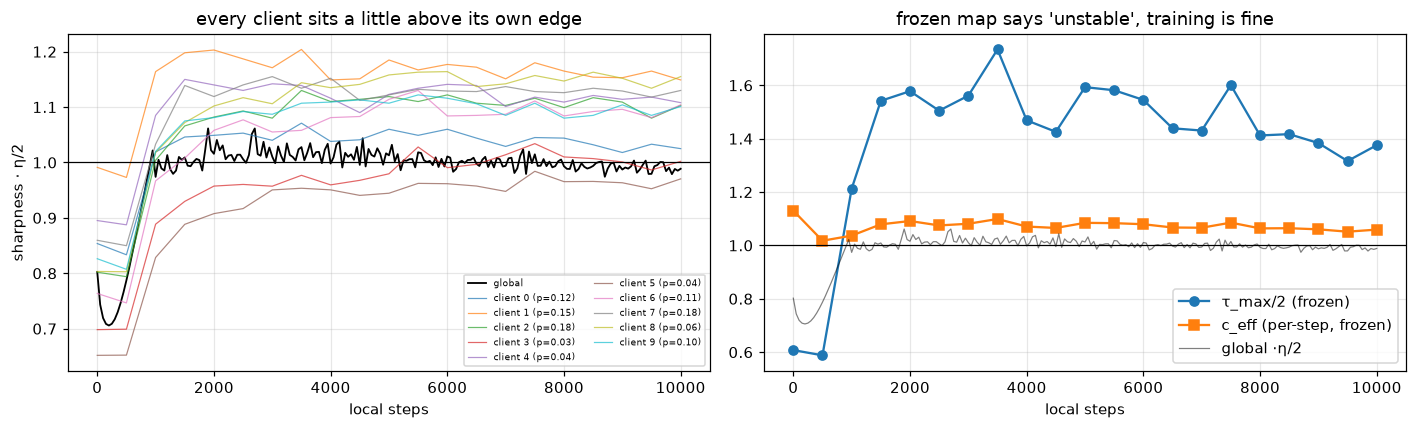

In [3]:
c = t.dropna(subset=["client_sharp"])
C = np.vstack(c.client_sharp.values) * lr / 2
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
ax = axes[0]
g = t.dropna(subset=["sharpness"])
ax.plot(g.steps, g.sharpness * lr / 2, "k", lw=1.2, label="global")
for i in range(C.shape[1]):
    ax.plot(c.steps, C[:, i], lw=0.8, alpha=0.7, label=f"client {i} (p={p[i]:.2f})")
edge_line(ax); ax.set_xlabel("local steps"); ax.set_ylabel("sharpness · η/2"); ax.legend(fontsize=6, ncol=2)
ax.set_title("every client sits a little above its own edge")
ax = axes[1]
r = t.dropna(subset=["tau_max"])
ax.plot(r.steps, r.tau_max / 2, "o-", label="τ_max/2 (frozen)")
ax.plot(r.steps, r.ceff_frozen, "s-", label="c_eff (per-step, frozen)")
ax.plot(g.steps, g.sharpness * lr / 2, "k", lw=0.8, alpha=0.5, label="global ·η/2")
edge_line(ax); ax.set_xlabel("local steps"); ax.legend(); ax.set_title("frozen map says 'unstable', training is fine")
plt.tight_layout(); plt.show()

In [4]:
tail = c[c.steps >= c.steps.max() * 0.7]
Ct = np.vstack(tail.client_sharp.values) * lr / 2
pd.DataFrame({"client": range(len(p)), "share p": p, "median sharpness·η/2 (last 30%)": np.median(Ct, 0)}).sort_values(
    "median sharpness·η/2 (last 30%)", ascending=False).round(3)

,client,share p,median sharpness·η/2 (last 30%)
1,1,0.152,1.154
8,8,0.056,1.152
7,7,0.179,1.129
4,4,0.038,1.114
2,2,0.178,1.103
6,6,0.114,1.092
9,9,0.097,1.085
0,0,0.119,1.032
3,3,0.026,1.007
5,5,0.041,0.965


## 2. A small overshoot becomes a large τ

One local step multiplies a client's sharp direction by `1 − ηλ = 1 − 2c` (c = sharpness·η/2). K steps multiply it by `(1 − 2c)ᴷ`. The frozen map assumes that factor holds for all K steps. If the clients' sharp directions were aligned, the round map's eigenvalue there would be about `Σ pᵢ (1 − (1 − 2cᵢ)ᴷ)`.

In [5]:
cs = np.median(Ct, 0)
tab = pd.DataFrame({"c (·η/2)": [1.0, 1.05, 1.1, 1.15, 1.2]})
tab["one step factor 1−2c"] = 1 - 2 * tab["c (·η/2)"]
for k in [2, 5, 10, 20]:
    tab[f"(1−2c)^{k}"] = tab["one step factor 1−2c"] ** k
display(tab.round(2))
aligned = np.sum(p * (1 - (1 - 2 * cs) ** K))
print(f"aligned-directions estimate of τ/2 from the measured clients: {aligned / 2:.2f}")
print(f"measured frozen τ_max/2 (median, last 30%): {r[r.steps >= r.steps.max() * 0.7].tau_max.median() / 2:.2f}")

,c (·η/2),one step factor 1−2c,(1−2c)^2,(1−2c)^5,(1−2c)^10,(1−2c)^20
0,1.00,-1.0,1.00,-1.00,1.00,1.00
1,1.05,-1.1,1.21,-1.61,2.59,6.73
2,1.10,-1.2,1.44,-2.49,6.19,38.34
3,1.15,-1.3,1.69,-3.71,13.79,190.05
4,1.20,-1.4,1.96,-5.38,28.93,836.68


aligned-directions estimate of τ/2 from the measured clients: 1.81
measured frozen τ_max/2 (median, last 30%): 1.41


## 3. τ_min early in training

In [6]:
r[["steps", "tau_min", "tau_max"]].head(4)

,steps,tau_min,tau_max
2216,0,-2.187,1.216
2226,500,-0.189,1.176
2236,1000,-0.211,2.425
2246,1500,-0.474,3.084


## Conclusions

1. **FedAvg reaches EoS:** global sharpness·η/2 settles at about 1.
2. **Each client sits slightly past its own edge** (about 1.1–1.2), like plain GD's overshoot.
3. **The frozen round map over-predicts instability.** τ_max/2 is well above 1 while training is stable. The reason is compounding: a 10–20% per-step overshoot raised to the K-th power (section 2). The aligned-directions estimate shows the same order of magnitude.
4. **τ_min is already negative at initialization,** before any client is past its edge. At K = 1 and early in training it mostly reflects negative curvature; at even K it carries over-edge clients (notebook 05).